In [2]:
# Import Data and Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("E:\\Credit_Scorecard\\data\\loan.csv",low_memory=False)

#### __Dropping Joint Applications__

In [46]:
# Dropping Joint Application Type
df_ind = data.loc[data['application_type'] != "JOINT"]
df_ind.shape

(886868, 74)

#### __Dropping loans issued before 2010__

In [47]:
# Transforming date columns from string to pandas datetime
# We are dropping loans issued before 2009 to avoid reflection of 2008 financial crisis. 
date_cols = ['issue_d','earliest_cr_line','next_pymnt_d']
for col in date_cols:
    df_ind[col] = pd.to_datetime(df_ind[col],format="%b-%Y",errors="coerce")
df_ind = df_ind.loc[df_ind['issue_d'].dt.year >= 2010]
df_ind.shape

(878591, 74)

#### __Missing & Zero Values__

In [48]:
"""
We are dropping columns including missing values more than 90 percent because the missingness is probably casued by some system issue. 
"""
for col in df_ind.columns:
    missing_pct = round((df_ind[col].isna().sum()/df_ind.shape[0])*100,4)
    if missing_pct > 90:
        df_ind = df_ind.drop(columns=col)

In [49]:
# Let's check the missing % in the rest of the columns
rest_miss_cols = [col for col in df_ind.columns if df_ind[col].isna().sum() > 0]
print("Missing Value Percentage")
print("="*40)
for col in rest_miss_cols:
    missing_pct = round((df_ind[col].isna().sum()/df_ind.shape[0])*100,4)
    print(f"{col}:{missing_pct}")

Missing Value Percentage
emp_title:5.7996
emp_length:5.095
desc:86.5781
title:0.0162
mths_since_last_delinq:51.1722
mths_since_last_record:84.6139
revol_util:0.0503
last_pymnt_d:1.9921
next_pymnt_d:28.0496
last_credit_pull_d:0.0057
mths_since_last_major_derog:74.7828
tot_coll_amt:7.0566
tot_cur_bal:7.0566
total_rev_hi_lim:7.0566


In [50]:
# Filling missing values
"""
Months since last delinquency or record (mths_since_last_delinq/mths_since_last_record/mths_since_last_major_derog): 
It is highly possible that majority of the borrowers do not 
have any delinquencies or public records or derogatory history. 
Therefore, we will fill NAs in months since last delinquency, record and derogatory by 0. 

Next payment date (next_pymnt_d): Missing because those loan were full paid or charged off.

"""
df_ind.loc[:,['mths_since_last_delinq','mths_since_last_record',
              'mths_since_last_major_derog']] = df_ind.loc[:,['mths_since_last_delinq','mths_since_last_record',
                                                              'mths_since_last_major_derog']].fillna(0)

In [51]:
# Zero value percentage
print("Zero Value Percent")
print("="*40)
for col in df_ind.columns:
    zero_val_pct = round((df_ind.loc[df_ind[col] == 0].shape[0]/df_ind.shape[0])*100,2)
    if zero_val_pct > 90:
        print(f"{col}:{zero_val_pct}") 

Zero Value Percent
total_rec_late_fee:98.66
recoveries:97.29
collection_recovery_fee:97.42
collections_12_mths_ex_med:98.67
acc_now_delinq:99.53


#### __Derived Variables__

In [ ]:
""" 
we can derive some new variables to increase model's discrimatory power and avoid loosing valuable information due to multicollinearity. 
"""
# Loan to income ratio > loan amount / annual income
df_ind['loan_to_annl_inc'] = df_ind['loan_amnt'].div(df_ind['annual_inc'],fill_value=0).round(2)

# The difference between the earliest credit line and issue date is the length of credit history
df_ind['credit_history_length'] = (df_ind['issue_d'].dt.year - df_ind['earliest_cr_line'].dt.year) * 12 + \
                                df_ind['issue_d'].dt.month - df_ind['earliest_cr_line'].dt.month

# Months Overdue 
df_ind['obs_d'] = pd.to_datetime("2016-01-01")
df_ind['MOD'] = (df_ind['obs_d'] - df_ind['next_pymnt_d']).dt.days / 30.25 

# Credit Default Flag
df_ind['default_flag'] = 0
df_ind.loc[(df_ind['loan_status'] == "Charged Off") | (df_ind['loan_status'] == "Default") | 
(df_ind['loan_status'] == "Does not meet the credit policy. Status:Charged Off"),'default_flag'] = 1
df_ind.loc[(df_ind['loan_status'] == "Late (31-120 days)") & 
    (df_ind['MOD'] >=4),"default_flag"] = 1
df_ind['default_flag'].value_counts(normalize=True)*100

default_flag
0    94.781303
1     5.218697
Name: proportion, dtype: float64

#### __Drop observations that contradicts business logic and clean columns__

In [53]:
# Dropping charged off loans with zero overdue months 
idx_drop = df_ind.loc[(df_ind['loan_status'] == "Charged Off") & (df_ind['MOD'] == 0)].index
df_ind = df_ind.drop(index = idx_drop)
df_ind.shape

(878591, 63)

In [54]:
# Dropping rows where months since last delinquency is greater than zero but delinquency in two years 
ilog_rows = df_ind.loc[(df_ind['mths_since_last_delinq'] <= 24) & (df_ind['mths_since_last_delinq'] !=0) & (df_ind['delinq_2yrs'] == 0)].index
df_ind = df_ind.drop(index = ilog_rows)
df_ind.shape

(871964, 63)

In [55]:
# Drop categories significantly fewer counts than the rest in home_ownership column
df_ind = df_ind[~df_ind['home_ownership'].isin(['OTHER', 'NONE', 'ANY'])]
df_ind.shape

(871870, 63)

In [56]:
df_ind['emp_length'] = df_ind['emp_length'].str.replace(r'[^\d]', '', regex=True)

In [57]:
df_ind['emp_length'] = pd.to_numeric(df_ind['emp_length'], errors='coerce') 

#### __Dropping Irrelevant Columns__

In [58]:
df_ind.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim

In [ ]:
""" 
We have derived new variables from loan_amnt, funded_amnt', funded_amnt_inv, open_acc, total_acc, 
and total_rec_prncp. Therefore, we no longer need them. 

Variables that provide same type of information

Recoveries and collection recovery fee are applicable only to charged off accoutns. 
They are not relevant for behavioral credit risk model. 

Account now delinquent has zero values more than 99.5 percent. 
Since final default status will be derived from loan status, this is not relevant. 

Dropping revol_bal, and tot_cur_bal because there are derived variables for them. 

identifiers, location info, and variables with high granunalirity will also be dropeed. 

Keeping term and interest rate but dropping intallment amount. 
"""

df_cleaned = df_ind.drop(columns=['loan_amnt', 'funded_amnt', 'funded_amnt_inv','total_rec_prncp','out_prncp_inv','total_pymnt','total_pymnt_inv',
                                'application_type','recoveries','collection_recovery_fee','id', 'member_id','installment','sub_grade',
                                'emp_title','pymnt_plan', 'url', 'desc','title', 'zip_code', 'addr_state','policy_code',
                                'revol_bal','last_credit_pull_d','last_pymnt_d','last_pymnt_amnt','obs_d','next_pymnt_d','MOD',
                                'acc_now_delinq','issue_d','earliest_cr_line','total_acc']) 

df_cleaned.shape

(871870, 30)

#### __Exploratory Data Analysis__

In [80]:
# Transforming amounts to thousands for better interpretability 
df_cleaned['annual_inc'] = df_cleaned['annual_inc']/1000 
df_cleaned['tot_coll_amt'] = df_cleaned['tot_coll_amt']/1000
df_cleaned['tot_cur_bal'] = df_cleaned['tot_cur_bal']/1000
df_cleaned['total_rev_hi_lim'] = df_cleaned['total_rev_hi_lim']/1000 

# Separating numerical and categorical columns
num_cols = df_cleaned.select_dtypes(include=[int, float]).columns
cat_cols = df_cleaned.select_dtypes(exclude=[int, float]).columns

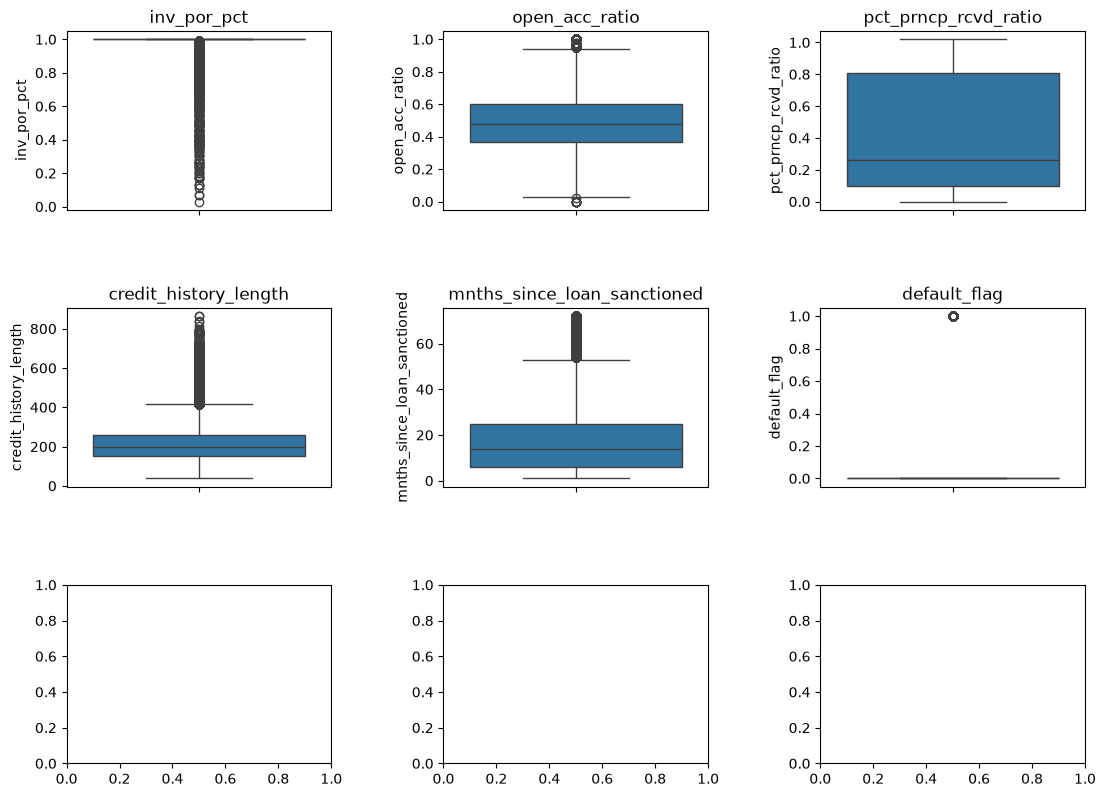

In [82]:
# Creating Boxplots to check for outliers
fig, axes = plt.subplots(3, 3, figsize=(12, 9))  # 3 rows, 3 columns
fig.tight_layout(pad=5.0)

# Flatten axes array for easier iteration
axes = axes.flatten()

# Loop through each variable and plot the boxplot
for i, var in enumerate(num_cols[18:]):
    sns.boxplot(data=df_cleaned, y=var, ax=axes[i])
    axes[i].set_title(f'{var}')

plt.show()

In [83]:
# Drop Outliers 
df_cleaned = df_cleaned.loc[~(df_cleaned['pub_rec'] > 40)]
df_cleaned = df_cleaned.loc[~(df_cleaned['revol_util'] > 150)]
df_cleaned = df_cleaned.loc[~(df_cleaned['mths_since_last_delinq'] > 150)]
df_cleaned = df_cleaned.loc[~(df_cleaned['total_rec_late_fee'] > 300)]
df_indf_cleanedd = df_cleaned.loc[~(df_cleaned['tot_coll_amt'] > 2000)]
df_cleaned = df_cleaned.loc[~(df_cleaned['tot_cur_bal'] > 5000)]
df_cleaned = df_cleaned.loc[~(df_cleaned['total_rev_hi_lim'] > 2000)]
df_cleaned.shape

(871829, 31)

#### __Distribution of numerical variables using violin plot__

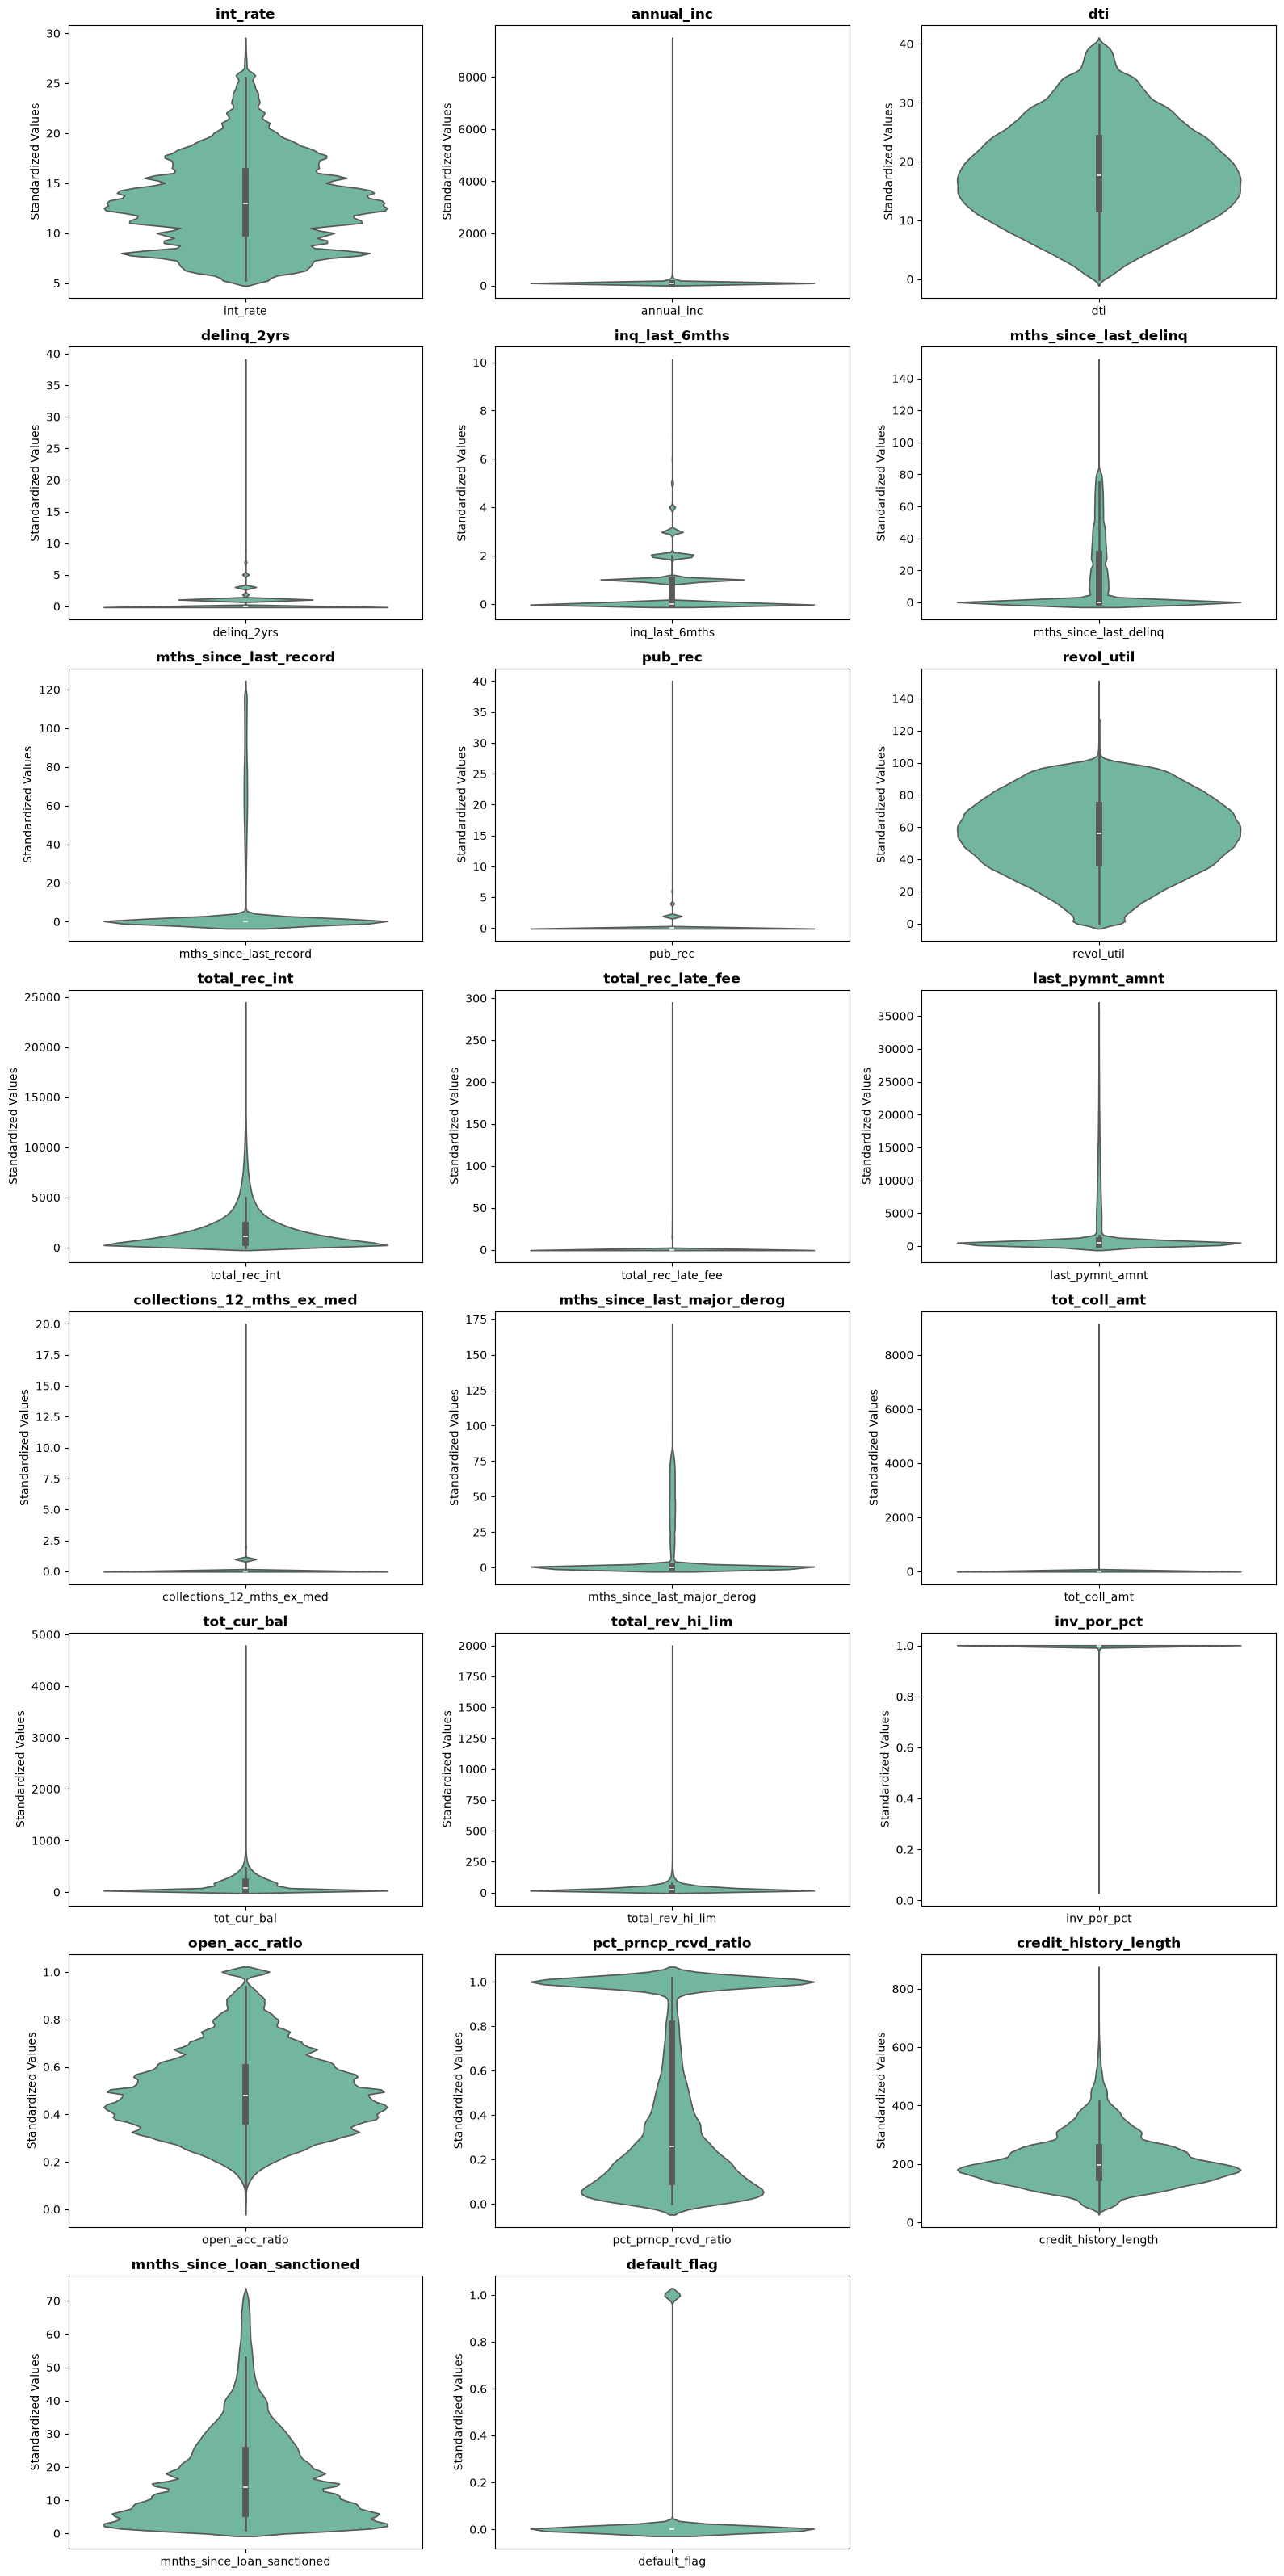

In [52]:
if num_cols is None:
    num_cols = df_cleaned.select_dtypes(include=[int, float]).columns
    
n_vars = len(num_cols)
n_cols = 3  # 3 columns
n_rows = (n_vars + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.violinplot(data=df_cleaned[[col]], ax=axes[idx], palette='Set2')
    axes[idx].set_title(col, fontweight='bold')
    axes[idx].set_ylabel('Standardized Values')

for idx in range(n_vars, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [84]:
df_cleaned.columns

Index(['term', 'int_rate', 'grade', 'emp_length', 'home_ownership',
       'annual_inc', 'verification_status', 'loan_status', 'purpose', 'dti',
       'delinq_2yrs', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'pub_rec', 'revol_util',
       'initial_list_status', 'total_rec_int', 'total_rec_late_fee',
       'last_pymnt_amnt', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'tot_coll_amt', 'tot_cur_bal',
       'total_rev_hi_lim', 'inv_por_pct', 'open_acc_ratio',
       'pct_prncp_rcvd_ratio', 'credit_history_length',
       'mnths_since_loan_sanctioned', 'default_flag'],
      dtype='str')

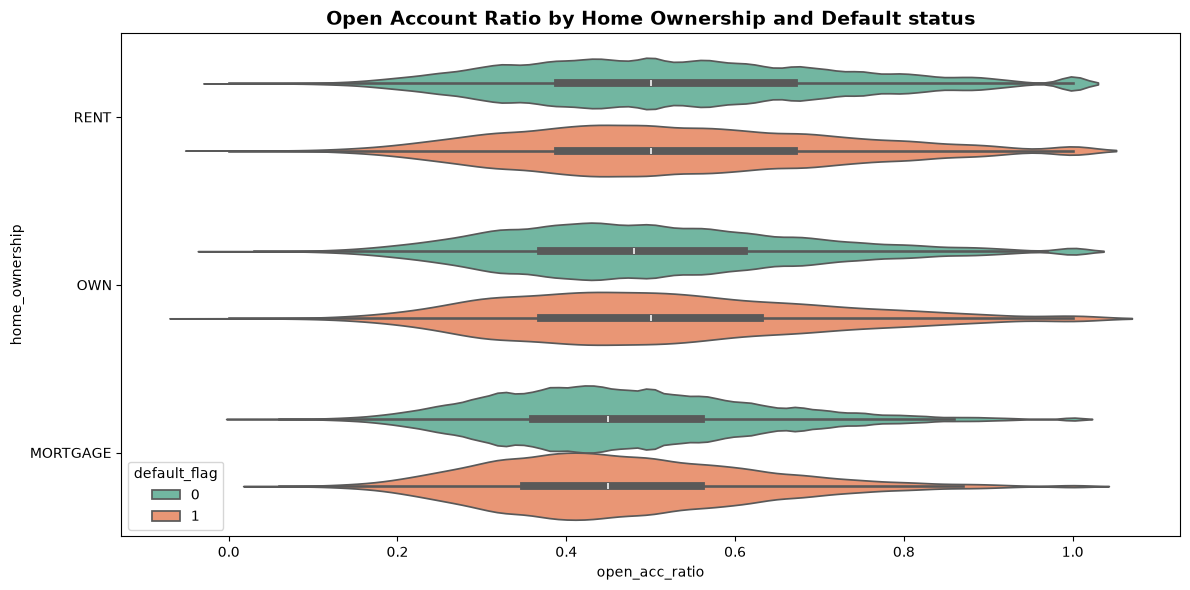

In [88]:
# Example: Loan Amount by Credit Tier and Default Status
fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=df_cleaned, x='open_acc_ratio', y='home_ownership', hue='default_flag', 
               ax=ax, palette='Set2', split=False)
ax.set_title('Open Account Ratio by Home Ownership and Default status', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()